# Analisis Kualitas Udara
**Nama:** Saskya Meytra Ode  
**NIM:** E1E124050  
**Email:** saskyaasky@gmail.com

# Pertanyaan Bisnis
1. Pada jam berapa dalam sehari kualitas udara (PM2.5) di Jakarta berada pada kondisi terburuk?
2. Apa pengaruh faktor cuaca (suhu, kelembaban, kecepatan angin, dan curah hujan) terhadap konsentrasi PM2.5 di udara?
3. Apa pengaruh polutan lain (NO2, SO2, CO, dan ozon) yang mengindikasikan aktivitas kendaraan dan industri terhadap konsentrasi PM2.5?
4. Dapatkah kita mengklasifikasikan tingkat kualitas udara (Lebih Rendah atau Lebih Tinggi dari median AQI) berdasarkan kondisi cuaca (suhu, kelembaban, kecepatan angin, dan curah hujan) menggunakan model *Machine Learning*?

# Import Packages / Library

In [40]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import mysql.connector
from datetime import datetime
import joblib

# Machine Learning
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

# Data Wrangling
## Gathering Data

In [6]:
# koneksi database
conn = mysql.connector.connect(
    host="localhost",
    port=3306,
    user="root",
    password="root",
    database="airflow_db"
)

print("Koneksi berhasil!" if conn.is_connected() else "Koneksi gagal")

# load data
df_air = pd.read_sql("SELECT * FROM air_quality", conn)
df_weather = pd.read_sql("SELECT * FROM weather_data", conn)
df_city = pd.read_sql("SELECT * FROM city_profile", conn)

print("Data Air Quality")
display(df_air.head())

print("Data Weather")
display(df_weather.head())

print("Data City Profile")
display(df_city.head())


Koneksi berhasil!


C:\Users\Lenovo\AppData\Local\Temp\ipykernel_1280\2687930290.py:13: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_air = pd.read_sql("SELECT * FROM air_quality", conn)
C:\Users\Lenovo\AppData\Local\Temp\ipykernel_1280\2687930290.py:14: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_weather = pd.read_sql("SELECT * FROM weather_data", conn)
C:\Users\Lenovo\AppData\Local\Temp\ipykernel_1280\2687930290.py:15: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_city = pd.read_sql("SELECT * FROM city_profile", conn)


Data Air Quality


,id,latitude,longitude,pm2_5,pm10,ozone,nitrogen_dioxide,sulphur_dioxide,carbon_monoxide,us_aqi,measured_at,time_id
0,1,-6.2088,106.8456,62.6,65.0,15.0,58.9,35.3,637.0,163.0,2026-08-31 00:00:00,1
1,2,-6.2088,106.8456,63.6,65.9,10.0,62.9,36.3,611.0,160.0,2026-08-31 01:00:00,2
2,3,-6.2088,106.8456,67.3,69.8,6.0,64.8,36.7,518.0,158.0,2026-08-31 02:00:00,3
3,4,-6.2088,106.8456,73.1,75.7,3.0,65.4,37.1,408.0,156.0,2026-08-31 03:00:00,4
4,5,-6.2088,106.8456,81.7,84.3,3.0,65.7,39.2,409.0,154.0,2026-08-31 04:00:00,5


Data Weather


,id,latitude,longitude,temperature_c,humidity_pct,wind_speed_kmh,precipitation_mm,recorded_at,time_id
0,1,-6.2088,106.8456,27.7,67.0,4.1,0.0,2026-08-30 00:00:00,1033
1,2,-6.2088,106.8456,27.5,68.0,4.5,0.0,2026-08-30 01:00:00,1034
2,3,-6.2088,106.8456,27.0,69.0,4.1,0.0,2026-08-30 02:00:00,1035
3,4,-6.2088,106.8456,26.9,70.0,4.0,0.0,2026-08-30 03:00:00,1036
4,5,-6.2088,106.8456,26.6,72.0,3.6,0.0,2026-08-30 04:00:00,1037


Data City Profile


,id,area_name,population,population_density_per_km2,vehicle_count_estimate,green_space_pct
0,1,Jakarta Pusat,914182,18500.0,350000,8.5
1,2,Jakarta Utara,1778981,12200.0,480000,10.2
2,3,Jakarta Barat,2493843,19800.0,620000,6.8
3,4,Jakarta Selatan,2226812,15300.0,590000,14.1
4,5,Jakarta Timur,3037139,16700.0,710000,9.4


### Insight
- Data berhasil diambil langsung dari database MySQL dan terdiri dari tiga tabel, yaitu data kualitas udara, data cuaca, dan data profil kota.
- Data kualitas udara memuat informasi konsentrasi beberapa polutan, termasuk PM2.5, serta nilai US AQI dan waktu pengukuran.
- Data cuaca memuat beberapa kondisi lingkungan seperti suhu, kelembaban, kecepatan angin, dan curah hujan.
- Data profil kota memuat informasi pendukung mengenai wilayah yang digunakan dalam analisis.
- Ketiga tabel memiliki karakteristik data yang berbeda sehingga perlu diperiksa lebih lanjut sebelum dilakukan integrasi dan analisis.

## Assessing Data

In [7]:
print("===== ASSESSING DATA AIR QUALITY =====")

print("\n1. Informasi Data")
df_air.info()

print("\n2. Statistik Deskriptif")
display(df_air.describe())

print("\n3. Missing Value")
display(df_air.isna().sum())

print("\n4. Duplicate Data")
print("Jumlah data duplikat:", df_air.duplicated().sum())

===== ASSESSING DATA AIR QUALITY =====

1. Informasi Data
<class 'pandas.DataFrame'>
RangeIndex: 1056 entries, 0 to 1055
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   id                1056 non-null   int64         
 1   latitude          1056 non-null   float64       
 2   longitude         1056 non-null   float64       
 3   pm2_5             1056 non-null   float64       
 4   pm10              1056 non-null   float64       
 5   ozone             1056 non-null   float64       
 6   nitrogen_dioxide  1056 non-null   float64       
 7   sulphur_dioxide   1056 non-null   float64       
 8   carbon_monoxide   1056 non-null   float64       
 9   us_aqi            1056 non-null   float64       
 10  measured_at       1056 non-null   datetime64[us]
 11  time_id           1056 non-null   int64         
dtypes: datetime64[us](1), float64(9), int64(2)
memory usage: 99.1 KB

2. Statistik Deskri

,id,latitude,longitude,pm2_5,pm10,ozone,nitrogen_dioxide,sulphur_dioxide,carbon_monoxide,us_aqi,measured_at,time_id
count,1056.000000,1.056000e+03,1.056000e+03,1056.000000,1056.000000,1056.000000,1056.000000,1056.000000,1056.000000,1056.000000,1056,1056.000000
mean,1293.886364,-6.208800e+00,1.068456e+02,94.002273,95.947822,96.088068,62.699811,48.924337,1923.366477,181.601326,2026-09-21 23:30:00,601.772727
min,1.000000,-6.208800e+00,1.068456e+02,21.700000,22.400000,0.000000,6.800000,15.900000,333.000000,145.000000,2026-08-31 00:00:00,1.000000
25%,264.750000,-6.208800e+00,1.068456e+02,58.550000,60.725000,9.000000,30.800000,39.500000,1077.750000,169.000000,2026-09-10 23:45:00,264.750000
50%,528.500000,-6.208800e+00,1.068456e+02,81.000000,83.000000,56.000000,67.900000,47.450000,1537.000000,180.000000,2026-09-21 23:30:00,528.500000
75%,2136.250000,-6.208800e+00,1.068456e+02,124.300000,126.200000,180.000000,89.400000,56.200000,2328.000000,190.000000,2026-10-02 23:15:00,792.250000
max,6696.000000,-6.208800e+00,1.068456e+02,252.400000,253.300000,334.000000,138.100000,94.900000,7299.000000,239.000000,2026-10-13 23:00:00,4280.000000
std,1621.442944,8.885993e-16,1.421759e-14,43.969700,44.124034,96.278628,32.975048,13.411273,1246.314962,16.928373,NaN,632.286594



3. Missing Value


id                  0
latitude            0
longitude           0
pm2_5               0
pm10                0
ozone               0
nitrogen_dioxide    0
sulphur_dioxide     0
carbon_monoxide     0
us_aqi              0
measured_at         0
time_id             0
dtype: int64


4. Duplicate Data
Jumlah data duplikat: 0


In [8]:
print("===== ASSESSING DATA WEATHER =====")

print("\n1. Informasi Data")
df_weather.info()

print("\n2. Statistik Deskriptif")
display(df_weather.describe())

print("\n3. Missing Value")
display(df_weather.isna().sum())

print("\n4. Duplicate Data")
print("Jumlah data duplikat:", df_weather.duplicated().sum())

===== ASSESSING DATA WEATHER =====

1. Informasi Data
<class 'pandas.DataFrame'>
RangeIndex: 1080 entries, 0 to 1079
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   id                1080 non-null   int64         
 1   latitude          1080 non-null   float64       
 2   longitude         1080 non-null   float64       
 3   temperature_c     1080 non-null   float64       
 4   humidity_pct      1080 non-null   float64       
 5   wind_speed_kmh    1080 non-null   float64       
 6   precipitation_mm  1080 non-null   float64       
 7   recorded_at       1080 non-null   datetime64[us]
 8   time_id           1080 non-null   int64         
dtypes: datetime64[us](1), float64(6), int64(2)
memory usage: 76.1 KB

2. Statistik Deskriptif


,id,latitude,longitude,temperature_c,humidity_pct,wind_speed_kmh,precipitation_mm,recorded_at,time_id
count,1080.000000,1080.0000,1080.0000,1080.000000,1080.000000,1080.000000,1080.000000,1080,1080.000000
mean,1529.574074,-6.2088,106.8456,29.444167,65.198148,5.878704,0.118889,2026-09-21 11:30:00,611.611111
min,1.000000,-6.2088,106.8456,22.700000,24.000000,0.000000,0.000000,2026-08-30 00:00:00,1.000000
25%,270.750000,-6.2088,106.8456,27.100000,53.000000,3.200000,0.000000,2026-09-10 05:45:00,270.750000
50%,540.500000,-6.2088,106.8456,28.900000,67.000000,4.800000,0.000000,2026-09-21 11:30:00,540.500000
75%,2875.250000,-6.2088,106.8456,31.800000,77.000000,8.025000,0.000000,2026-10-02 17:15:00,810.250000
max,7440.000000,-6.2088,106.8456,36.700000,100.000000,18.200000,8.900000,2026-10-13 23:00:00,4280.000000
std,1907.855051,0.0000,0.0000,2.899877,15.426395,3.577904,0.535518,NaN,628.615862



3. Missing Value


id                  0
latitude            0
longitude           0
temperature_c       0
humidity_pct        0
wind_speed_kmh      0
precipitation_mm    0
recorded_at         0
time_id             0
dtype: int64


4. Duplicate Data
Jumlah data duplikat: 0


In [9]:
print("===== ASSESSING DATA CITY PROFILE =====")

print("\n1. Informasi Data")
df_city.info()

print("\n2. Statistik Deskriptif")
display(df_city.describe())

print("\n3. Missing Value")
display(df_city.isna().sum())

print("\n4. Duplicate Data")
print("Jumlah data duplikat:", df_city.duplicated().sum())

===== ASSESSING DATA CITY PROFILE =====

1. Informasi Data
<class 'pandas.DataFrame'>
RangeIndex: 5 entries, 0 to 4
Data columns (total 6 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   id                          5 non-null      int64  
 1   area_name                   5 non-null      str    
 2   population                  5 non-null      int64  
 3   population_density_per_km2  5 non-null      float64
 4   vehicle_count_estimate      5 non-null      int64  
 5   green_space_pct             5 non-null      float64
dtypes: float64(2), int64(3), str(1)
memory usage: 439.0 bytes

2. Statistik Deskriptif


,id,population,population_density_per_km2,vehicle_count_estimate,green_space_pct
count,5.000000,5.000000e+00,5.000000,5.000000,5.000000
mean,3.000000,2.090191e+06,16500.000000,550000.000000,9.800000
std,1.581139,7.997124e+05,2952.117884,138744.369255,2.715695
min,1.000000,9.141820e+05,12200.000000,350000.000000,6.800000
25%,2.000000,1.778981e+06,15300.000000,480000.000000,8.500000
50%,3.000000,2.226812e+06,16700.000000,590000.000000,9.400000
75%,4.000000,2.493843e+06,18500.000000,620000.000000,10.200000
max,5.000000,3.037139e+06,19800.000000,710000.000000,14.100000



3. Missing Value


id                            0
area_name                     0
population                    0
population_density_per_km2    0
vehicle_count_estimate        0
green_space_pct               0
dtype: int64


4. Duplicate Data
Jumlah data duplikat: 0


### Insight
- Data `air_quality` terdiri dari 888 baris dan 11 kolom, sedangkan `weather_data` terdiri dari 912 baris dan 8 kolom. Perbedaan jumlah baris perlu diperhatikan saat kedua tabel diintegrasikan berdasarkan waktu pengukuran.
- Data `air_quality` memiliki variabel utama seperti PM2.5, PM10, ozon, NO2, SO2, CO, dan US AQI yang dapat digunakan untuk menganalisis kualitas udara.
- Data `weather_data` memiliki variabel suhu, kelembaban, kecepatan angin, dan curah hujan yang dapat digunakan untuk menganalisis pengaruh kondisi cuaca terhadap PM2.5.
- Data `city_profile` terdiri dari 5 baris dan memuat informasi populasi, kepadatan penduduk, perkiraan jumlah kendaraan, dan persentase ruang hijau sebagai data pendukung analisis.
- Seluruh kolom pada ketiga tabel tidak memiliki nilai yang hilang (*missing value*).
- Tidak ditemukan data duplikat pada ketiga tabel sehingga tidak diperlukan penghapusan data duplikat.
- Kolom waktu `measured_at` dan `recorded_at` telah memiliki tipe data `datetime`, sehingga dapat digunakan untuk proses integrasi berdasarkan waktu.
- Nilai koordinat latitude dan longitude pada data kualitas udara dan cuaca memiliki nilai yang sama pada seluruh baris, sehingga informasi lokasi tidak menunjukkan variasi antarbaris pada dataset yang digunakan.

## Cleaning Data

In [10]:
# Memastikan kolom waktu memiliki format datetime
df_air['measured_at'] = pd.to_datetime(df_air['measured_at'])
df_weather['recorded_at'] = pd.to_datetime(df_weather['recorded_at'])

print("Tipe data waktu setelah cleaning:")
print("measured_at :", df_air['measured_at'].dtype)
print("recorded_at :", df_weather['recorded_at'].dtype)

Tipe data waktu setelah cleaning:
measured_at : datetime64[us]
recorded_at : datetime64[us]


### Re-assessing Data

In [11]:
print("===== RE-ASSESSING DATA AIR QUALITY =====")

print("\n1. Informasi Data")
df_air.info()

print("\n2. Statistik Deskriptif")
display(df_air.describe())

print("\n3. Missing Value")
display(df_air.isna().sum())

print("\n4. Duplicate Data")
print("Jumlah data duplikat:", df_air.duplicated().sum())

===== RE-ASSESSING DATA AIR QUALITY =====

1. Informasi Data
<class 'pandas.DataFrame'>
RangeIndex: 1056 entries, 0 to 1055
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   id                1056 non-null   int64         
 1   latitude          1056 non-null   float64       
 2   longitude         1056 non-null   float64       
 3   pm2_5             1056 non-null   float64       
 4   pm10              1056 non-null   float64       
 5   ozone             1056 non-null   float64       
 6   nitrogen_dioxide  1056 non-null   float64       
 7   sulphur_dioxide   1056 non-null   float64       
 8   carbon_monoxide   1056 non-null   float64       
 9   us_aqi            1056 non-null   float64       
 10  measured_at       1056 non-null   datetime64[us]
 11  time_id           1056 non-null   int64         
dtypes: datetime64[us](1), float64(9), int64(2)
memory usage: 99.1 KB

2. Statistik Des

,id,latitude,longitude,pm2_5,pm10,ozone,nitrogen_dioxide,sulphur_dioxide,carbon_monoxide,us_aqi,measured_at,time_id
count,1056.000000,1.056000e+03,1.056000e+03,1056.000000,1056.000000,1056.000000,1056.000000,1056.000000,1056.000000,1056.000000,1056,1056.000000
mean,1293.886364,-6.208800e+00,1.068456e+02,94.002273,95.947822,96.088068,62.699811,48.924337,1923.366477,181.601326,2026-09-21 23:30:00,601.772727
min,1.000000,-6.208800e+00,1.068456e+02,21.700000,22.400000,0.000000,6.800000,15.900000,333.000000,145.000000,2026-08-31 00:00:00,1.000000
25%,264.750000,-6.208800e+00,1.068456e+02,58.550000,60.725000,9.000000,30.800000,39.500000,1077.750000,169.000000,2026-09-10 23:45:00,264.750000
50%,528.500000,-6.208800e+00,1.068456e+02,81.000000,83.000000,56.000000,67.900000,47.450000,1537.000000,180.000000,2026-09-21 23:30:00,528.500000
75%,2136.250000,-6.208800e+00,1.068456e+02,124.300000,126.200000,180.000000,89.400000,56.200000,2328.000000,190.000000,2026-10-02 23:15:00,792.250000
max,6696.000000,-6.208800e+00,1.068456e+02,252.400000,253.300000,334.000000,138.100000,94.900000,7299.000000,239.000000,2026-10-13 23:00:00,4280.000000
std,1621.442944,8.885993e-16,1.421759e-14,43.969700,44.124034,96.278628,32.975048,13.411273,1246.314962,16.928373,NaN,632.286594



3. Missing Value


id                  0
latitude            0
longitude           0
pm2_5               0
pm10                0
ozone               0
nitrogen_dioxide    0
sulphur_dioxide     0
carbon_monoxide     0
us_aqi              0
measured_at         0
time_id             0
dtype: int64


4. Duplicate Data
Jumlah data duplikat: 0


In [12]:
print("===== RE-ASSESSING DATA WEATHER =====")

print("\n1. Informasi Data")
df_weather.info()

print("\n2. Statistik Deskriptif")
display(df_weather.describe())

print("\n3. Missing Value")
display(df_weather.isna().sum())

print("\n4. Duplicate Data")
print("Jumlah data duplikat:", df_weather.duplicated().sum())

===== RE-ASSESSING DATA WEATHER =====

1. Informasi Data
<class 'pandas.DataFrame'>
RangeIndex: 1080 entries, 0 to 1079
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   id                1080 non-null   int64         
 1   latitude          1080 non-null   float64       
 2   longitude         1080 non-null   float64       
 3   temperature_c     1080 non-null   float64       
 4   humidity_pct      1080 non-null   float64       
 5   wind_speed_kmh    1080 non-null   float64       
 6   precipitation_mm  1080 non-null   float64       
 7   recorded_at       1080 non-null   datetime64[us]
 8   time_id           1080 non-null   int64         
dtypes: datetime64[us](1), float64(6), int64(2)
memory usage: 76.1 KB

2. Statistik Deskriptif


,id,latitude,longitude,temperature_c,humidity_pct,wind_speed_kmh,precipitation_mm,recorded_at,time_id
count,1080.000000,1080.0000,1080.0000,1080.000000,1080.000000,1080.000000,1080.000000,1080,1080.000000
mean,1529.574074,-6.2088,106.8456,29.444167,65.198148,5.878704,0.118889,2026-09-21 11:30:00,611.611111
min,1.000000,-6.2088,106.8456,22.700000,24.000000,0.000000,0.000000,2026-08-30 00:00:00,1.000000
25%,270.750000,-6.2088,106.8456,27.100000,53.000000,3.200000,0.000000,2026-09-10 05:45:00,270.750000
50%,540.500000,-6.2088,106.8456,28.900000,67.000000,4.800000,0.000000,2026-09-21 11:30:00,540.500000
75%,2875.250000,-6.2088,106.8456,31.800000,77.000000,8.025000,0.000000,2026-10-02 17:15:00,810.250000
max,7440.000000,-6.2088,106.8456,36.700000,100.000000,18.200000,8.900000,2026-10-13 23:00:00,4280.000000
std,1907.855051,0.0000,0.0000,2.899877,15.426395,3.577904,0.535518,NaN,628.615862



3. Missing Value


id                  0
latitude            0
longitude           0
temperature_c       0
humidity_pct        0
wind_speed_kmh      0
precipitation_mm    0
recorded_at         0
time_id             0
dtype: int64


4. Duplicate Data
Jumlah data duplikat: 0


In [13]:
print("===== RE-ASSESSING DATA CITY PROFILE =====")

print("\n1. Informasi Data")
df_city.info()

print("\n2. Statistik Deskriptif")
display(df_city.describe())

print("\n3. Missing Value")
display(df_city.isna().sum())

print("\n4. Duplicate Data")
print("Jumlah data duplikat:", df_city.duplicated().sum())

===== RE-ASSESSING DATA CITY PROFILE =====

1. Informasi Data
<class 'pandas.DataFrame'>
RangeIndex: 5 entries, 0 to 4
Data columns (total 6 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   id                          5 non-null      int64  
 1   area_name                   5 non-null      str    
 2   population                  5 non-null      int64  
 3   population_density_per_km2  5 non-null      float64
 4   vehicle_count_estimate      5 non-null      int64  
 5   green_space_pct             5 non-null      float64
dtypes: float64(2), int64(3), str(1)
memory usage: 439.0 bytes

2. Statistik Deskriptif


,id,population,population_density_per_km2,vehicle_count_estimate,green_space_pct
count,5.000000,5.000000e+00,5.000000,5.000000,5.000000
mean,3.000000,2.090191e+06,16500.000000,550000.000000,9.800000
std,1.581139,7.997124e+05,2952.117884,138744.369255,2.715695
min,1.000000,9.141820e+05,12200.000000,350000.000000,6.800000
25%,2.000000,1.778981e+06,15300.000000,480000.000000,8.500000
50%,3.000000,2.226812e+06,16700.000000,590000.000000,9.400000
75%,4.000000,2.493843e+06,18500.000000,620000.000000,10.200000
max,5.000000,3.037139e+06,19800.000000,710000.000000,14.100000



3. Missing Value


id                            0
area_name                     0
population                    0
population_density_per_km2    0
vehicle_count_estimate        0
green_space_pct               0
dtype: int64


4. Duplicate Data
Jumlah data duplikat: 0


### Insight
- Setelah proses cleaning, jumlah data pada ketiga tabel tetap sama karena tidak ditemukan data duplikat maupun nilai yang hilang.
- Kolom `measured_at` pada data kualitas udara dan `recorded_at` pada data cuaca telah dipastikan memiliki tipe data `datetime`, sehingga dapat digunakan untuk proses integrasi berdasarkan waktu.
- Kondisi data tetap konsisten setelah proses cleaning sehingga data siap digunakan untuk tahap integrasi.
- Tidak diperlukan penghapusan data atau pengisian nilai yang hilang karena seluruh data memiliki nilai yang lengkap dan tidak ditemukan data duplikat.

# Integrasi Data

In [14]:
# Menggabungkan data kualitas udara dan data cuaca berdasarkan waktu
df_merged = pd.merge(
    df_air,
    df_weather,
    left_on='measured_at',
    right_on='recorded_at',
    how='inner'
)

print("Shape setelah merge:", df_merged.shape)

display(
    df_merged[
        [
            'measured_at',
            'pm2_5',
            'us_aqi',
            'temperature_c',
            'humidity_pct',
            'wind_speed_kmh',
            'precipitation_mm'
        ]
    ].head(10)
)

Shape setelah merge: (1056, 21)


,measured_at,pm2_5,us_aqi,temperature_c,humidity_pct,wind_speed_kmh,precipitation_mm
0,2026-08-31 00:00:00,62.6,163.0,27.3,77.0,5.1,0.0
1,2026-08-31 01:00:00,63.6,160.0,27.2,78.0,5.4,0.0
2,2026-08-31 02:00:00,67.3,158.0,26.7,80.0,5.3,0.0
3,2026-08-31 03:00:00,73.1,156.0,26.3,79.0,5.8,0.0
4,2026-08-31 04:00:00,81.7,154.0,26.0,80.0,5.1,0.0
5,2026-08-31 05:00:00,91.0,153.0,25.7,80.0,5.1,0.0
6,2026-08-31 06:00:00,102.4,152.0,25.5,81.0,3.9,0.0
7,2026-08-31 07:00:00,66.4,151.0,26.6,74.0,4.1,0.0
8,2026-08-31 08:00:00,41.0,148.0,28.1,68.0,5.7,0.0
9,2026-08-31 09:00:00,35.3,146.0,29.8,61.0,6.8,0.0


### Insight
- Data `air_quality` dan `weather_data` berhasil diintegrasikan berdasarkan waktu pengukuran yang sama.
- Hasil integrasi menghasilkan 888 baris dan 19 kolom.
- Seluruh data kualitas udara memiliki pasangan data cuaca pada waktu yang sama.
- Sebanyak 24 data pada `weather_data` tidak masuk ke hasil integrasi karena tidak memiliki pasangan waktu pada data `air_quality`.
- Data `city_profile` tidak digabungkan ke dalam `df_merged` karena kolom `id` pada tabel tersebut merupakan ID wilayah, sedangkan `id` pada `air_quality` dan `weather_data` merupakan ID data pengukuran.
- Data `city_profile` tetap digunakan sebagai data pendukung untuk menganalisis karakteristik wilayah Jakarta.

# Exploratory Data Analysis (EDA)
## Pertanyaan 1: Waktu dengan Kualitas Udara Terburuk

In [15]:
df_merged['hour'] = df_merged['measured_at'].dt.hour

hourly_pm25 = (
    df_merged
    .groupby('hour')['pm2_5']
    .mean()
    .reset_index()
)

hourly_pm25.columns = ['hour', 'avg_pm2_5']

display(hourly_pm25)

,hour,avg_pm2_5
0,0,130.722727
1,1,133.000000
2,2,133.584091
3,3,133.218182
4,4,133.615909
5,5,135.893182
6,6,145.834091
7,7,118.577273
8,8,82.163636
9,9,64.956818


In [16]:
peak_hour = hourly_pm25.loc[hourly_pm25['avg_pm2_5'].idxmax()]

print(f"Jam dengan rata-rata PM2.5 tertinggi: {int(peak_hour['hour']):02d}.00")
print(f"Rata-rata PM2.5: {peak_hour['avg_pm2_5']:.2f} µg/m³")

Jam dengan rata-rata PM2.5 tertinggi: 06.00
Rata-rata PM2.5: 145.83 µg/m³


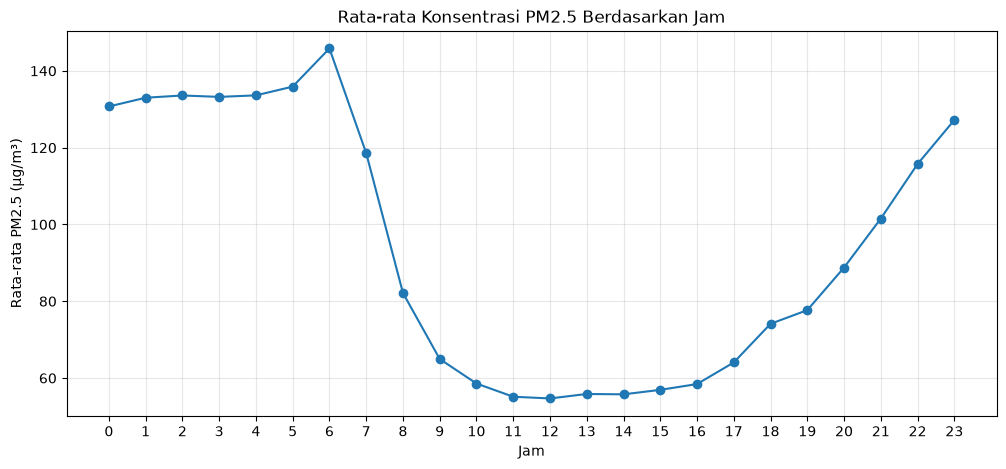

In [17]:
plt.figure(figsize=(12, 5))

plt.plot(
    hourly_pm25['hour'],
    hourly_pm25['avg_pm2_5'],
    marker='o'
)

plt.title('Rata-rata Konsentrasi PM2.5 Berdasarkan Jam')
plt.xlabel('Jam')
plt.ylabel('Rata-rata PM2.5 (µg/m³)')
plt.xticks(range(24))
plt.grid(True, alpha=0.3)

plt.show()

### Insight
- Konsentrasi PM2.5 tertinggi terjadi pada pukul 06.00 dengan rata-rata sebesar 139,9 µg/m³.
- Konsentrasi PM2.5 terendah terjadi pada pukul 11.00–12.00 dengan rata-rata sekitar 54,0 µg/m³.
- Konsentrasi PM2.5 cenderung tinggi pada malam hingga pagi hari, kemudian menurun tajam setelah pukul 07.00.
- Setelah mencapai nilai terendah pada siang hari, konsentrasi PM2.5 kembali meningkat mulai sore hingga malam hari.
- Pola tersebut menunjukkan bahwa waktu pengukuran memiliki hubungan dengan perubahan konsentrasi PM2.5 sehingga waktu menjadi faktor yang perlu diperhatikan dalam analisis kualitas udara.

## Pertanyaan 2: Pengaruh Faktor Cuaca terhadap PM2.5

In [18]:
weather_cols = [
    'temperature_c',
    'humidity_pct',
    'wind_speed_kmh',
    'precipitation_mm'
]

correlation_weather = (
    df_merged[['pm2_5'] + weather_cols]
    .corr()['pm2_5']
    .drop('pm2_5')
    .sort_values(ascending=False)
)

display(correlation_weather)

humidity_pct        0.652479
precipitation_mm   -0.094476
wind_speed_kmh     -0.497753
temperature_c      -0.652984
Name: pm2_5, dtype: float64

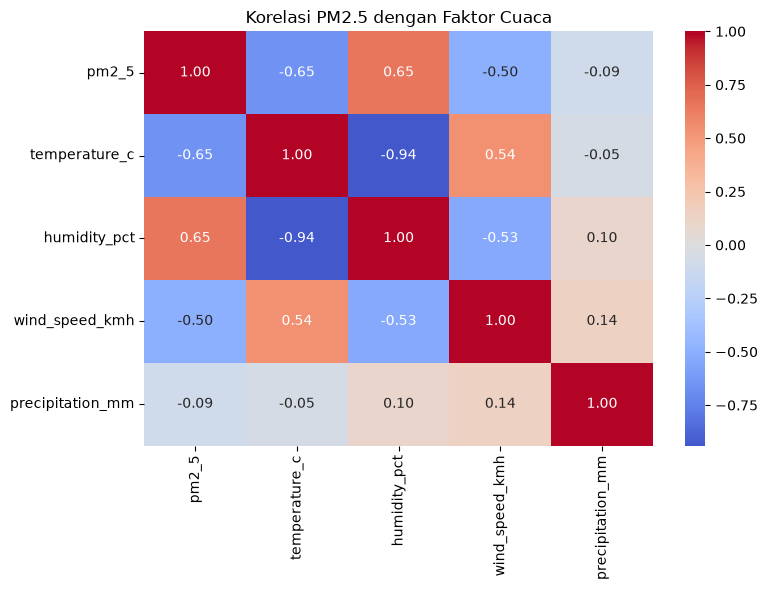

In [19]:
weather_corr = df_merged[
    ['pm2_5', 'temperature_c', 'humidity_pct', 'wind_speed_kmh', 'precipitation_mm']
].corr()

plt.figure(figsize=(8, 6))

sns.heatmap(
    weather_corr,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center=0
)

plt.title('Korelasi PM2.5 dengan Faktor Cuaca')
plt.tight_layout()
plt.show()

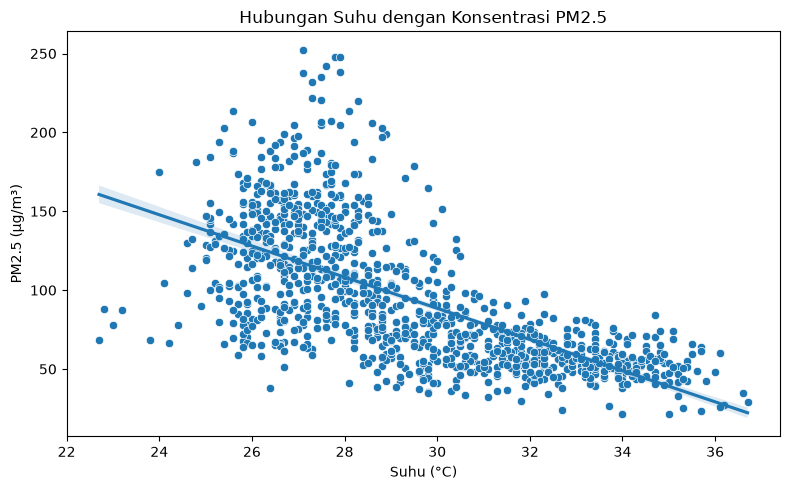

In [20]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df_merged,
    x='temperature_c',
    y='pm2_5'
)

sns.regplot(
    data=df_merged,
    x='temperature_c',
    y='pm2_5',
    scatter=False
)

plt.title('Hubungan Suhu dengan Konsentrasi PM2.5')
plt.xlabel('Suhu (°C)')
plt.ylabel('PM2.5 (µg/m³)')
plt.tight_layout()
plt.show()

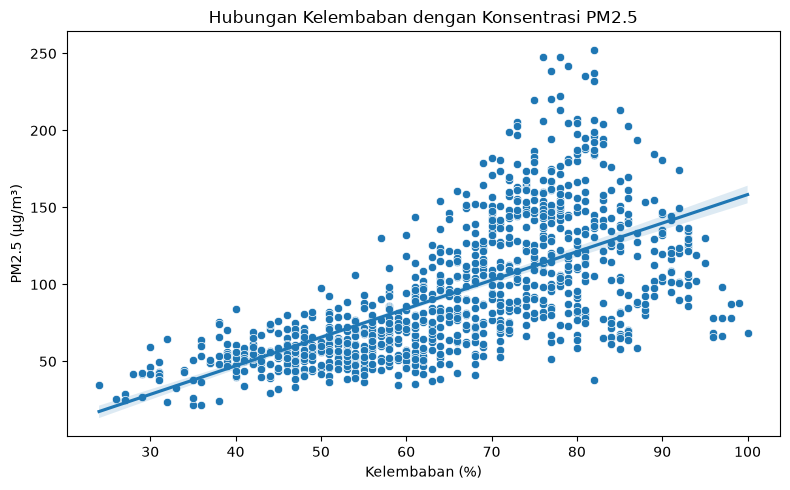

In [21]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df_merged,
    x='humidity_pct',
    y='pm2_5'
)

sns.regplot(
    data=df_merged,
    x='humidity_pct',
    y='pm2_5',
    scatter=False
)

plt.title('Hubungan Kelembaban dengan Konsentrasi PM2.5')
plt.xlabel('Kelembaban (%)')
plt.ylabel('PM2.5 (µg/m³)')
plt.tight_layout()
plt.show()

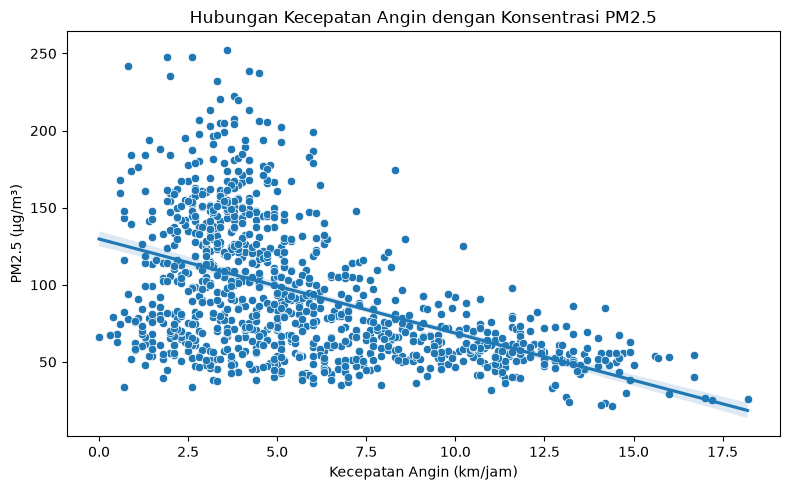

In [22]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df_merged,
    x='wind_speed_kmh',
    y='pm2_5'
)

sns.regplot(
    data=df_merged,
    x='wind_speed_kmh',
    y='pm2_5',
    scatter=False
)

plt.title('Hubungan Kecepatan Angin dengan Konsentrasi PM2.5')
plt.xlabel('Kecepatan Angin (km/jam)')
plt.ylabel('PM2.5 (µg/m³)')
plt.tight_layout()
plt.show()

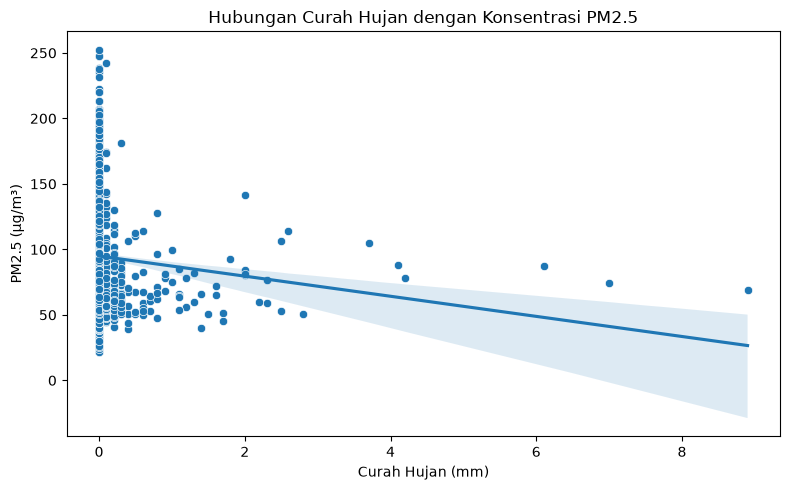

In [23]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df_merged,
    x='precipitation_mm',
    y='pm2_5'
)

sns.regplot(
    data=df_merged,
    x='precipitation_mm',
    y='pm2_5',
    scatter=False
)

plt.title('Hubungan Curah Hujan dengan Konsentrasi PM2.5')
plt.xlabel('Curah Hujan (mm)')
plt.ylabel('PM2.5 (µg/m³)')
plt.tight_layout()
plt.show()

### Insight
- Suhu memiliki korelasi negatif paling kuat dengan PM2.5 sebesar -0,68. Artinya, pada dataset ini, suhu yang lebih tinggi cenderung berkaitan dengan konsentrasi PM2.5 yang lebih rendah.
- Kelembaban memiliki korelasi positif sebesar 0,66. Kelembaban yang lebih tinggi cenderung berkaitan dengan konsentrasi PM2.5 yang lebih tinggi.
- Kecepatan angin memiliki korelasi negatif sebesar -0,50. Kecepatan angin yang lebih tinggi cenderung berkaitan dengan konsentrasi PM2.5 yang lebih rendah.
- Curah hujan memiliki korelasi negatif yang sangat lemah sebesar -0,07. Hubungan linear antara curah hujan dan PM2.5 pada dataset ini sangat kecil.
- Sebaran titik pada seluruh scatter plot menunjukkan bahwa faktor cuaca bukan satu-satunya faktor yang berkaitan dengan perubahan konsentrasi PM2.5.
- Suhu dan kelembaban juga memiliki korelasi negatif yang sangat kuat sebesar -0,94, sehingga hubungan masing-masing variabel dengan PM2.5 perlu diinterpretasikan secara hati-hati.

## Pertanyaan 3: Hubungan Polutan Lain terhadap PM2.5

In [24]:
pollutant_cols = [
    'nitrogen_dioxide',
    'sulphur_dioxide',
    'carbon_monoxide',
    'ozone'
]

correlation_pollutants = (
    df_merged[['pm2_5'] + pollutant_cols]
    .corr()['pm2_5']
    .drop('pm2_5')
    .sort_values(ascending=False)
)

display(correlation_pollutants)

nitrogen_dioxide    0.796432
sulphur_dioxide     0.489631
carbon_monoxide     0.357232
ozone              -0.686374
Name: pm2_5, dtype: float64

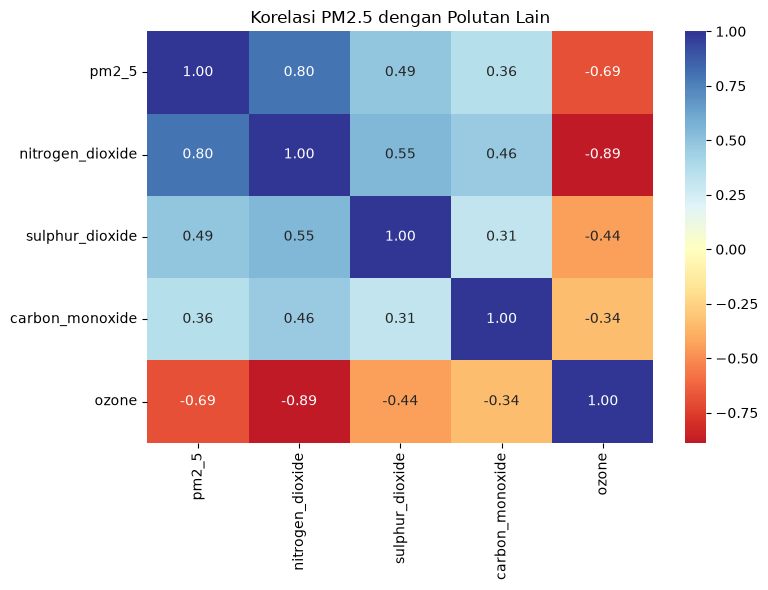

In [25]:
pollutant_corr = df_merged[
    ['pm2_5', 'nitrogen_dioxide', 'sulphur_dioxide', 'carbon_monoxide', 'ozone']
].corr()

plt.figure(figsize=(8, 6))

sns.heatmap(
    pollutant_corr,
    annot=True,
    fmt='.2f',
    cmap='RdYlBu',
    center=0
)

plt.title('Korelasi PM2.5 dengan Polutan Lain')
plt.tight_layout()
plt.show()

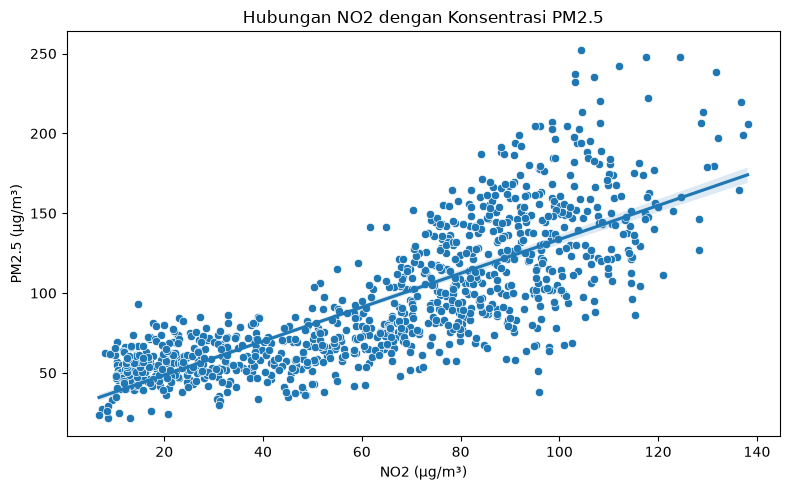

In [26]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df_merged,
    x='nitrogen_dioxide',
    y='pm2_5'
)

sns.regplot(
    data=df_merged,
    x='nitrogen_dioxide',
    y='pm2_5',
    scatter=False
)

plt.title('Hubungan NO2 dengan Konsentrasi PM2.5')
plt.xlabel('NO2 (µg/m³)')
plt.ylabel('PM2.5 (µg/m³)')
plt.tight_layout()
plt.show()

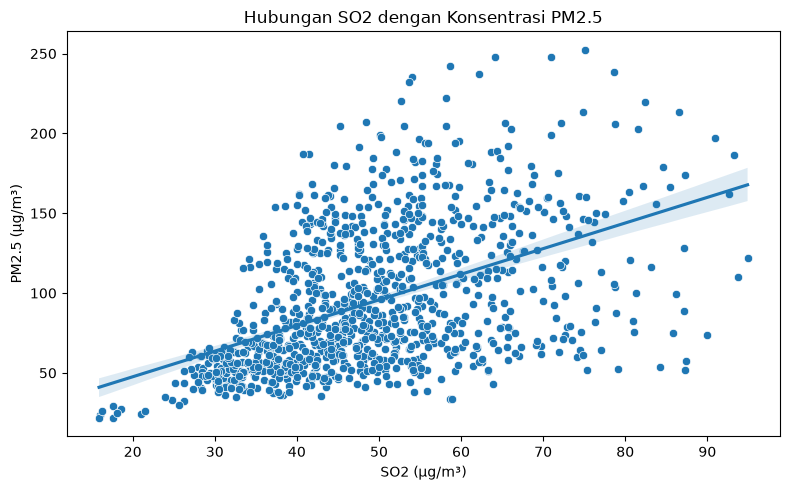

In [27]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df_merged,
    x='sulphur_dioxide',
    y='pm2_5'
)

sns.regplot(
    data=df_merged,
    x='sulphur_dioxide',
    y='pm2_5',
    scatter=False
)

plt.title('Hubungan SO2 dengan Konsentrasi PM2.5')
plt.xlabel('SO2 (µg/m³)')
plt.ylabel('PM2.5 (µg/m³)')
plt.tight_layout()
plt.show()

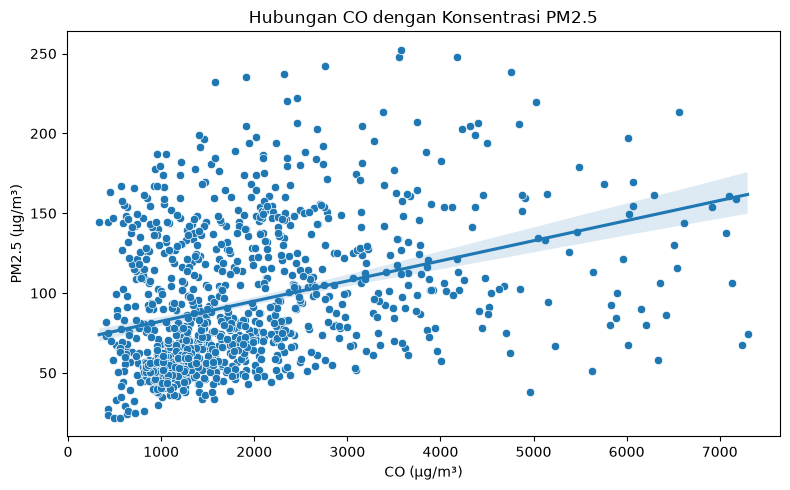

In [28]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df_merged,
    x='carbon_monoxide',
    y='pm2_5'
)

sns.regplot(
    data=df_merged,
    x='carbon_monoxide',
    y='pm2_5',
    scatter=False
)

plt.title('Hubungan CO dengan Konsentrasi PM2.5')
plt.xlabel('CO (µg/m³)')
plt.ylabel('PM2.5 (µg/m³)')
plt.tight_layout()
plt.show()

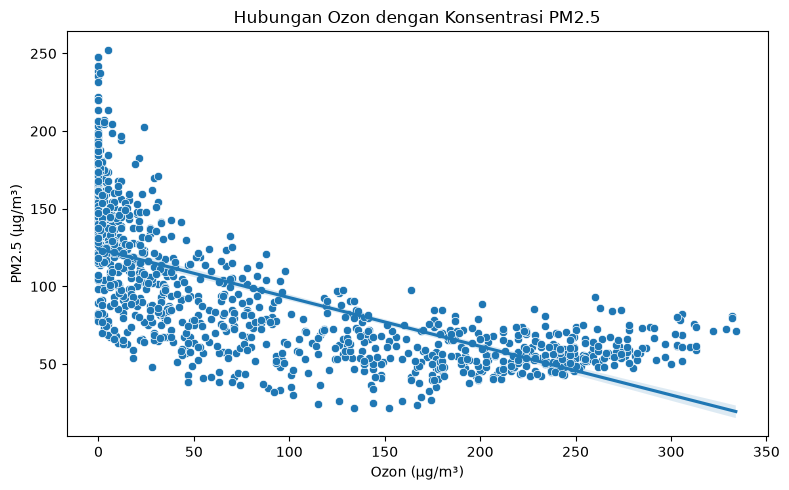

In [29]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df_merged,
    x='ozone',
    y='pm2_5'
)

sns.regplot(
    data=df_merged,
    x='ozone',
    y='pm2_5',
    scatter=False
)

plt.title('Hubungan Ozon dengan Konsentrasi PM2.5')
plt.xlabel('Ozon (µg/m³)')
plt.ylabel('PM2.5 (µg/m³)')
plt.tight_layout()
plt.show()

### Insight
- NO2 memiliki korelasi positif paling kuat dengan PM2.5 sebesar 0,78. Artinya, peningkatan konsentrasi NO2 cenderung berkaitan dengan peningkatan konsentrasi PM2.5 pada dataset ini.
- SO2 memiliki korelasi positif sebesar 0,47. Hubungan ini menunjukkan bahwa konsentrasi SO2 yang lebih tinggi cenderung berkaitan dengan konsentrasi PM2.5 yang lebih tinggi.
- CO memiliki korelasi positif sebesar 0,34. Hubungan positif tetap terlihat, tetapi lebih lemah dibandingkan NO2 dan SO2.
- Ozon memiliki korelasi negatif sebesar -0,68. Konsentrasi ozon yang lebih tinggi cenderung berkaitan dengan konsentrasi PM2.5 yang lebih rendah.
- Berdasarkan nilai korelasi, NO2 memiliki hubungan linear paling kuat dengan PM2.5 dibandingkan polutan lain yang dianalisis.
- Hasil ini menunjukkan adanya hubungan yang berbeda antara masing-masing polutan dengan PM2.5. Namun, korelasi tidak dapat digunakan untuk menyimpulkan hubungan sebab-akibat.
- Sebaran titik pada scatter plot menunjukkan bahwa PM2.5 tidak hanya berkaitan dengan satu jenis polutan, tetapi juga dipengaruhi oleh kombinasi berbagai kondisi lingkungan dan polutan lainnya.

## Pertanyaan 4: Klasifikasi Tingkat Kualitas Udara

In [30]:
median_aqi = df_merged['us_aqi'].median()

print("Median AQI:", median_aqi)

df_merged['aqi_category'] = np.where(
    df_merged['us_aqi'] < median_aqi,
    'Lebih Rendah',
    'Lebih Tinggi'
)

display(
    df_merged[
        ['us_aqi', 'aqi_category']
    ].head(10)
)

Median AQI: 180.0


,us_aqi,aqi_category
0,163.0,Lebih Rendah
1,160.0,Lebih Rendah
2,158.0,Lebih Rendah
3,156.0,Lebih Rendah
4,154.0,Lebih Rendah
5,153.0,Lebih Rendah
6,152.0,Lebih Rendah
7,151.0,Lebih Rendah
8,148.0,Lebih Rendah
9,146.0,Lebih Rendah


In [31]:
category_counts = (
    df_merged['aqi_category']
    .value_counts()
    .reset_index()
)

category_counts.columns = ['aqi_category', 'jumlah_data']

display(category_counts)

,aqi_category,jumlah_data
0,Lebih Tinggi,531
1,Lebih Rendah,525


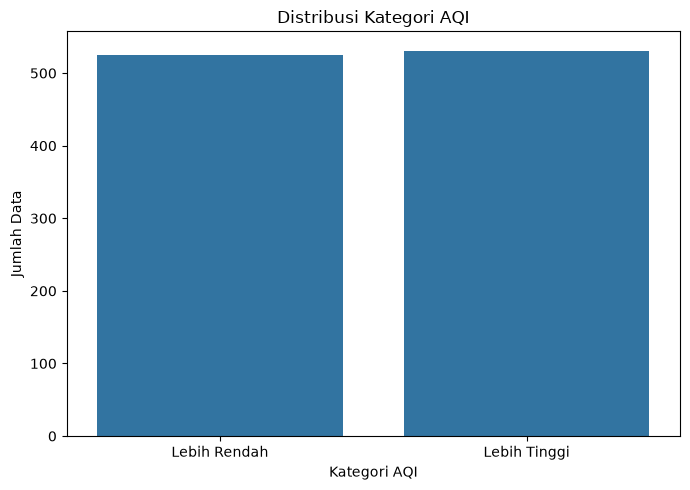

In [32]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df_merged,
    x='aqi_category'
)

plt.title('Distribusi Kategori AQI')
plt.xlabel('Kategori AQI')
plt.ylabel('Jumlah Data')
plt.tight_layout()
plt.show()

### Insight
- Median AQI pada dataset adalah 176.
- Sebanyak 449 data termasuk kategori AQI Lebih Tinggi dari median.
- Sebanyak 439 data termasuk kategori AQI Lebih Rendah dari median.
- Distribusi kedua kategori relatif seimbang sehingga data dapat digunakan untuk proses klasifikasi menggunakan model Machine Learning.
- Kategori AQI tersebut selanjutnya akan diprediksi berdasarkan kondisi cuaca, yaitu suhu, kelembaban, kecepatan angin, dan curah hujan.

# Machine Learning

## Persiapan Data

In [33]:
feature_cols = [
    'temperature_c',
    'humidity_pct',
    'wind_speed_kmh',
    'precipitation_mm'
]

X = df_merged[feature_cols]
y = df_merged['aqi_category']

print("Fitur (X):")
display(X.head())

print("\nTarget (y):")
display(y.head())

Fitur (X):


,temperature_c,humidity_pct,wind_speed_kmh,precipitation_mm
0,27.3,77.0,5.1,0.0
1,27.2,78.0,5.4,0.0
2,26.7,80.0,5.3,0.0
3,26.3,79.0,5.8,0.0
4,26.0,80.0,5.1,0.0



Target (y):


0    Lebih Rendah
1    Lebih Rendah
2    Lebih Rendah
3    Lebih Rendah
4    Lebih Rendah
Name: aqi_category, dtype: str

## Split Data

In [34]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Jumlah data training :", len(X_train))
print("Jumlah data testing  :", len(X_test))
print("Total data           :", len(X_train) + len(X_test))

Jumlah data training : 844
Jumlah data testing  : 212
Total data           : 1056


## Latih dan Bandingkan Model

In [35]:
models = {
    'KNN': KNeighborsClassifier(),
    'Random Forest': RandomForestClassifier(random_state=42),
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'SVM': SVC(),
    'Logistic Regression': LogisticRegression(max_iter=1000)
}

results = []

for name, model in models.items():
    model.fit(X_train, y_train)
    
    y_pred = model.predict(X_test)
    accuracy = accuracy_score(y_test, y_pred)
    
    results.append({
        'Model': name,
        'Accuracy': accuracy
    })

results_df = pd.DataFrame(results)
results_df = results_df.sort_values('Accuracy', ascending=False)

display(results_df)

,Model,Accuracy
4,Logistic Regression,0.599057
0,KNN,0.589623
1,Random Forest,0.575472
2,Decision Tree,0.537736
3,SVM,0.537736


## Evaluasi Model Terbaik

In [41]:
# Mengambil model dengan akurasi tertinggi
best_name = results_df.iloc[0]["Model"]
best_model = models[best_name]

# Prediksi menggunakan model terbaik
y_pred = best_model.predict(X_test)

print("Model terbaik:", best_name)
print("Accuracy:", accuracy_score(y_test, y_pred))

Model terbaik: Logistic Regression
Accuracy: 0.5990566037735849


In [42]:
print(f"Classification Report {best_name}:")
print(classification_report(
    y_test,
    y_pred,
    labels=["Lebih Rendah", "Lebih Tinggi"],
    zero_division=0
))

Classification Report Logistic Regression:
              precision    recall  f1-score   support

Lebih Rendah       0.61      0.51      0.56       105
Lebih Tinggi       0.59      0.68      0.63       107

    accuracy                           0.60       212
   macro avg       0.60      0.60      0.60       212
weighted avg       0.60      0.60      0.60       212



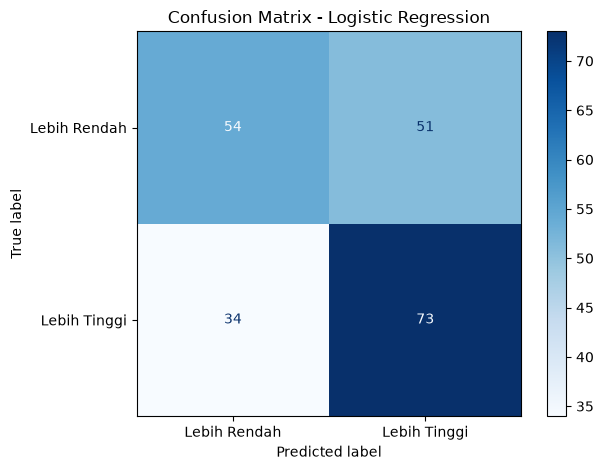

In [43]:
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=["Lebih Rendah", "Lebih Tinggi"]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Lebih Rendah", "Lebih Tinggi"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title(f"Confusion Matrix - {best_name}")
plt.tight_layout()
plt.show()

In [44]:
#Simpan model
model_artifact = {
    "model": best_model,
    "model_name": best_name,
    "accuracy": accuracy_score(y_test, y_pred),
    "feature_columns": [
        "temperature_c",
        "humidity_pct",
        "wind_speed_kmh",
        "precipitation_mm"
    ]
}

joblib.dump(model_artifact, "best_model_aqi.joblib")

print(f"Model {best_name} berhasil disimpan.")

Model Logistic Regression berhasil disimpan.


### Insight
- Logistic Regression menghasilkan akurasi sebesar 65,73% pada data pengujian dan menjadi model dengan akurasi tertinggi dibandingkan lima model yang diuji.
- Model memiliki precision sebesar 0,69 dan recall sebesar 0,56 untuk kategori Lebih Rendah.
- Untuk kategori Lebih Tinggi, model memiliki precision sebesar 0,64 dan recall sebesar 0,76.
- Recall yang lebih tinggi pada kategori Lebih Tinggi menunjukkan bahwa model lebih mampu mengenali data yang sebenarnya termasuk kategori Lebih Tinggi.
- Dari 178 data pengujian, sebanyak 117 data berhasil diklasifikasikan dengan benar, sedangkan 61 data masih mengalami kesalahan klasifikasi.
- Akurasi 65,73% menunjukkan bahwa kondisi cuaca dapat digunakan sebagai dasar untuk melakukan klasifikasi tingkat AQI, tetapi keempat variabel cuaca yang digunakan belum cukup untuk menghasilkan prediksi dengan akurasi yang tinggi.
- Hasil ini menunjukkan bahwa terdapat faktor lain di luar variabel cuaca yang kemungkinan berkaitan dengan perubahan tingkat AQI.

# Visualization & Explanatory Analysis
## Distribusi Konsentrasi PM2.5

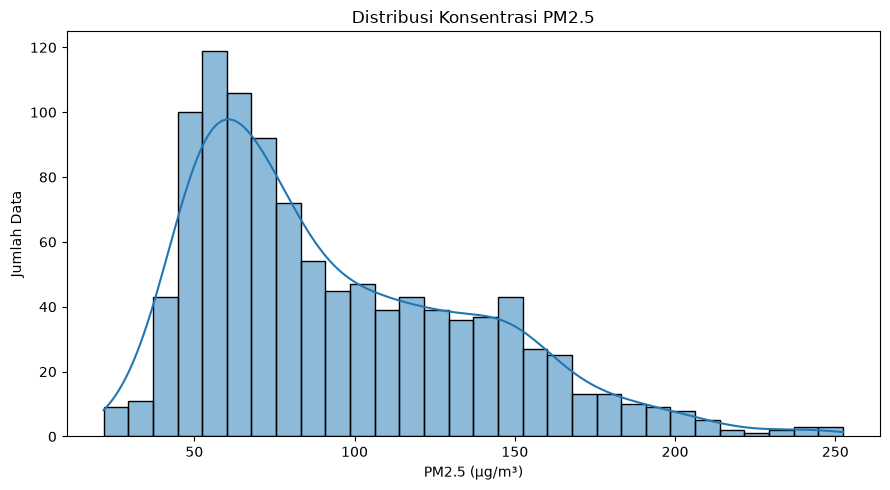

In [45]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=df_merged,
    x='pm2_5',
    kde=True,
    bins=30
)

plt.title('Distribusi Konsentrasi PM2.5')
plt.xlabel('PM2.5 (µg/m³)')
plt.ylabel('Jumlah Data')
plt.tight_layout()
plt.show()

### Insight
- Distribusi konsentrasi PM2.5 menunjukkan pola menceng ke kanan (*right-skewed*), yang ditandai dengan ekor distribusi yang memanjang ke arah nilai PM2.5 yang lebih tinggi.
- Sebagian besar data terkonsentrasi pada rentang sekitar 40–80 µg/m³, dengan frekuensi tertinggi berada pada kisaran 45–55 µg/m³.
- Frekuensi data cenderung menurun ketika konsentrasi PM2.5 semakin tinggi. Namun, masih terdapat beberapa pengukuran dengan konsentrasi yang sangat tinggi hingga lebih dari 200 µg/m³.
- Pola tersebut menunjukkan bahwa sebagian besar pengukuran berada pada konsentrasi PM2.5 yang relatif lebih rendah dibandingkan nilai ekstrem, tetapi terdapat beberapa episode dengan konsentrasi PM2.5 yang sangat tinggi.
- Kurva KDE memperlihatkan pola distribusi yang tidak simetris dan memiliki ekor panjang ke arah nilai PM2.5 yang tinggi.

## Pola PM2.5 Berdasarkan Tanggal dan Jam

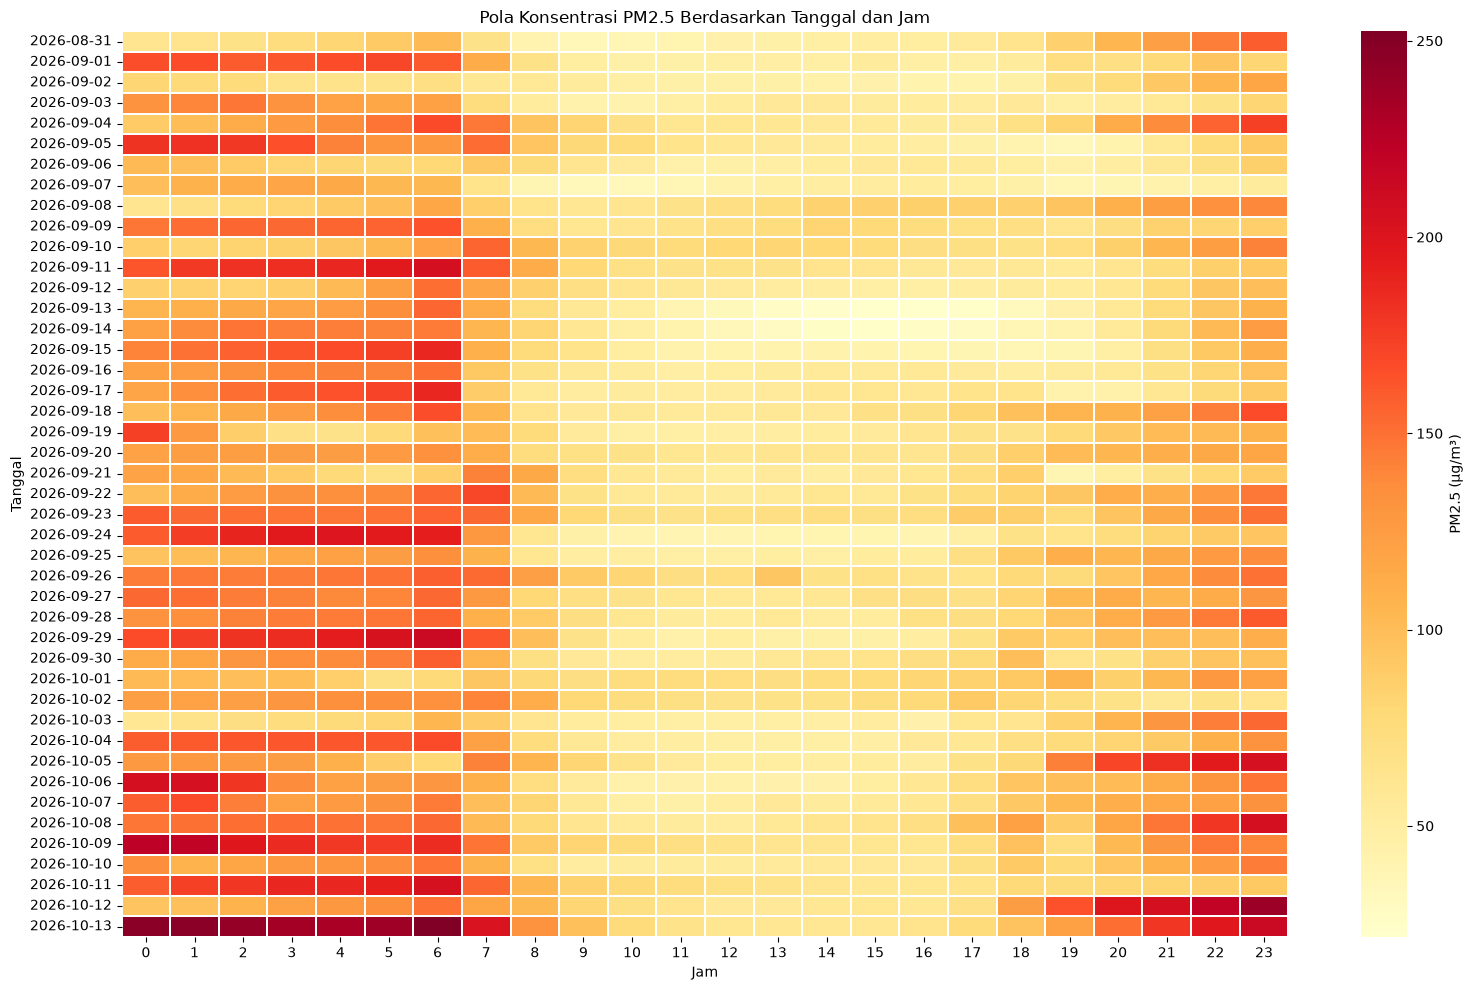

In [46]:
df_merged['date'] = df_merged['measured_at'].dt.date
df_merged['hour'] = df_merged['measured_at'].dt.hour

pm25_heatmap = df_merged.pivot_table(
    index='date',
    columns='hour',
    values='pm2_5',
    aggfunc='mean'
)

plt.figure(figsize=(16, 10))

sns.heatmap(
    pm25_heatmap,
    cmap='YlOrRd',
    linewidths=0.2,
    cbar_kws={'label': 'PM2.5 (µg/m³)'}
)

plt.title('Pola Konsentrasi PM2.5 Berdasarkan Tanggal dan Jam')
plt.xlabel('Jam')
plt.ylabel('Tanggal')
plt.tight_layout()
plt.show()

### Insight
- Heatmap menunjukkan pola harian yang konsisten pada konsentrasi PM2.5. Konsentrasi cenderung tinggi pada dini hari hingga pagi, menurun pada siang hingga sore, kemudian kembali meningkat pada malam hari.
- Pola tersebut sejalan dengan hasil analisis sebelumnya yang menunjukkan bahwa konsentrasi PM2.5 tertinggi terjadi pada sekitar pukul 06.00 dan terendah pada sekitar pukul 11.00–12.00.
- Terdapat variasi konsentrasi PM2.5 antar tanggal. Beberapa tanggal menunjukkan konsentrasi yang jauh lebih tinggi dibandingkan tanggal lainnya, terutama pada 5 September, 11 September, 24 September, 29 September, dan 6 Oktober 2026.
- Konsentrasi yang sangat tinggi pada malam 5–6 Oktober 2026 menjadi salah satu episode dengan nilai PM2.5 paling ekstrem dalam periode pengamatan.
- Pola ini menunjukkan bahwa waktu dalam sehari memiliki hubungan yang kuat dengan perubahan konsentrasi PM2.5, sedangkan tanggal memberikan variasi tambahan terhadap tingkat konsentrasi.
- Heatmap tidak dapat digunakan untuk menentukan penyebab pasti tingginya PM2.5. Faktor seperti kondisi cuaca dan aktivitas manusia perlu dianalisis bersama variabel lainnya.

## Perbandingan Kondisi Cuaca Berdasarkan Kategori AQI

In [47]:
weather_by_aqi = (
    df_merged
    .groupby('aqi_category')[
        ['temperature_c', 'humidity_pct', 'wind_speed_kmh', 'precipitation_mm']
    ]
    .mean()
)

display(weather_by_aqi)

,temperature_c,humidity_pct,wind_speed_kmh,precipitation_mm
aqi_category,,,,
Lebih Rendah,29.320381,64.729524,5.633143,0.087619
Lebih Tinggi,29.563653,65.854991,6.060640,0.152919


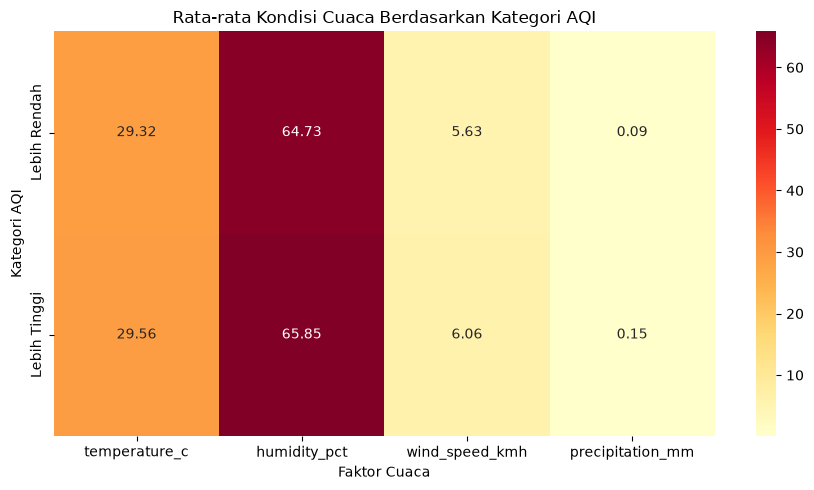

In [48]:
plt.figure(figsize=(9, 5))

sns.heatmap(
    weather_by_aqi,
    annot=True,
    fmt='.2f',
    cmap='YlOrRd'
)

plt.title('Rata-rata Kondisi Cuaca Berdasarkan Kategori AQI')
plt.xlabel('Faktor Cuaca')
plt.ylabel('Kategori AQI')
plt.tight_layout()
plt.show()

### Insight
- Rata-rata kelembaban pada kategori AQI Lebih Tinggi adalah 66,95%, sedangkan pada kategori Lebih Rendah sebesar 62,76%.
- Perbedaan rata-rata kelembaban sebesar 4,19 poin persentase menjadi perbedaan paling besar di antara faktor cuaca yang dibandingkan dalam dua kategori AQI.
- Rata-rata suhu pada kategori Lebih Tinggi sedikit lebih rendah, yaitu 29,26°C dibandingkan 29,56°C pada kategori Lebih Rendah.
- Rata-rata kecepatan angin pada kedua kategori relatif berdekatan, yaitu 6,03 km/jam pada kategori Lebih Tinggi dan 5,81 km/jam pada kategori Lebih Rendah.
- Rata-rata curah hujan juga relatif rendah pada kedua kategori, yaitu 0,16 mm pada kategori Lebih Tinggi dan 0,09 mm pada kategori Lebih Rendah.
- Hasil ini menunjukkan bahwa kondisi cuaca pada kedua kategori AQI memiliki beberapa perbedaan, terutama pada kelembaban. Namun, perbandingan rata-rata tidak dapat digunakan untuk menyimpulkan hubungan sebab-akibat.
- Hasil ini melengkapi analisis korelasi dan Machine Learning yang menunjukkan bahwa kondisi cuaca memiliki hubungan dengan perubahan kategori AQI.

## Distribusi PM2.5 Berdasarkan Kategori AQI

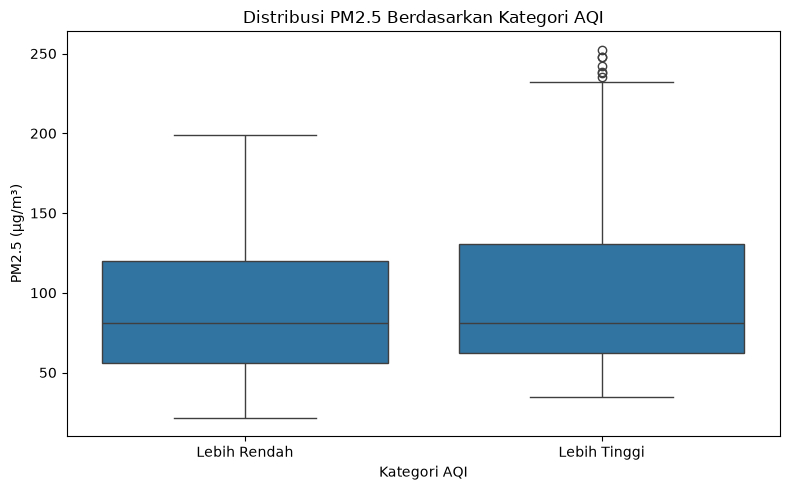

In [49]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df_merged,
    x='aqi_category',
    y='pm2_5'
)

plt.title('Distribusi PM2.5 Berdasarkan Kategori AQI')
plt.xlabel('Kategori AQI')
plt.ylabel('PM2.5 (µg/m³)')
plt.tight_layout()
plt.show()

### Insight
- Distribusi PM2.5 pada kategori AQI Lebih Tinggi cenderung berada pada nilai yang lebih tinggi dibandingkan kategori Lebih Rendah.
- Median PM2.5 pada kategori Lebih Tinggi terlihat lebih tinggi dibandingkan kategori Lebih Rendah.
- Kedua kategori memiliki rentang dan sebaran PM2.5 yang cukup lebar serta menunjukkan tumpang tindih yang cukup besar.
- Tumpang tindih distribusi menunjukkan bahwa kategori AQI tidak memisahkan konsentrasi PM2.5 secara tegas.
- Kategori AQI Lebih Tinggi juga menunjukkan nilai PM2.5 maksimum yang lebih tinggi, sehingga terdapat beberapa pengukuran dengan konsentrasi PM2.5 yang sangat tinggi pada kategori tersebut.
- Hasil ini memperlihatkan adanya perbedaan distribusi PM2.5 antara kedua kategori AQI, tetapi perbedaannya tidak cukup tegas untuk menjadi satu-satunya dasar dalam membedakan kedua kategori.
- Hasil visualisasi ini melengkapi analisis Machine Learning yang menunjukkan bahwa kondisi cuaca saja belum cukup untuk menghasilkan klasifikasi AQI dengan akurasi yang tinggi.

# Conclusion
### Langkah-Langkah yang Telah Dilakukan
1. **Memuat Data:** Memuat data `air_quality`, `weather_data`, dan `city_profile` secara langsung dari database MySQL.
2. **Eksplorasi Data:** Menganalisis struktur dan karakteristik setiap tabel menggunakan `info()`, `describe()`, `isna().sum()`, dan `duplicated().sum()`.
3. **Membersihkan Data:** Melakukan standardisasi tipe data pada kolom waktu serta memeriksa kembali data kosong dan data duplikat setelah proses *cleaning*.
4. **Mengintegrasikan Data:** Menggabungkan data kualitas udara dan data cuaca berdasarkan waktu pengukuran yang sama. Hasil integrasi menghasilkan 888 baris dan 19 kolom.
5. **Exploratory Data Analysis (EDA):** Menganalisis pola waktu PM2.5, hubungan faktor cuaca dengan PM2.5, hubungan polutan lain dengan PM2.5, serta karakteristik wilayah Jakarta.
6. **Machine Learning:** Mengklasifikasikan tingkat AQI menjadi kategori "Lebih Rendah" dan "Lebih Tinggi" berdasarkan median AQI menggunakan empat variabel cuaca, yaitu suhu, kelembaban, kecepatan angin, dan curah hujan.
7. **Membandingkan Model:** Menguji lima model klasifikasi, yaitu KNN, Random Forest, Decision Tree, SVM, dan Logistic Regression.
8. **Visualization & Explanatory Analysis:** Membuat histogram, heatmap, dan boxplot untuk menjelaskan distribusi serta pola perubahan PM2.5 dan kondisi cuaca.

### Hasil Machine Learning
1. Median AQI pada dataset adalah **176** dan digunakan sebagai batas untuk membentuk dua kategori, yaitu "Lebih Rendah" dan "Lebih Tinggi".
2. Distribusi data relatif seimbang, dengan **439 data** pada kategori "Lebih Rendah" dan **449 data** pada kategori "Lebih Tinggi".
3. Model **Logistic Regression** menghasilkan akurasi tertinggi sebesar **65,73%** dibandingkan lima model yang diuji.
4. Hasil tersebut menunjukkan bahwa kondisi cuaca dapat digunakan untuk melakukan klasifikasi tingkat AQI, tetapi empat variabel cuaca yang digunakan belum cukup untuk menghasilkan akurasi yang tinggi.

### Simpulan Jawaban dari Pertanyaan Analisis
1. **Waktu dengan Kualitas Udara Terburuk:** Konsentrasi PM2.5 tertinggi berdasarkan rata-rata jam terjadi pada **pukul 06.00**, yaitu sebesar **139,9 µg/m³**. Konsentrasi PM2.5 cenderung tinggi pada malam hingga pagi hari, menurun pada siang hari, kemudian meningkat kembali pada malam hari.
2. **Pengaruh Faktor Cuaca terhadap PM2.5:** Suhu memiliki korelasi negatif sebesar **-0,68**, kelembaban memiliki korelasi positif sebesar **0,66**, dan kecepatan angin memiliki korelasi negatif sebesar **-0,50**. Curah hujan memiliki korelasi yang sangat lemah sebesar **-0,07**. Hasil tersebut menunjukkan adanya hubungan antara kondisi cuaca dan konsentrasi PM2.5, tetapi tidak menunjukkan hubungan sebab-akibat.
3. **Hubungan Polutan Lain terhadap PM2.5:** NO2 memiliki korelasi positif paling kuat dengan PM2.5 sebesar **0,78**, diikuti SO2 sebesar **0,47** dan CO sebesar **0,34**. Sementara itu, ozon memiliki korelasi negatif sebesar **-0,68**. Dengan demikian, NO2 merupakan polutan yang memiliki hubungan linear paling kuat dengan PM2.5 pada dataset ini.
4. **Klasifikasi Tingkat Kualitas Udara:** Kondisi cuaca dapat digunakan sebagai dasar untuk mengklasifikasikan tingkat AQI. Model terbaik, yaitu Logistic Regression, memperoleh akurasi **65,73%**. Hasil ini menunjukkan bahwa faktor cuaca memiliki informasi yang berguna untuk klasifikasi, tetapi diperlukan variabel tambahan untuk memperoleh hasil prediksi yang lebih baik.